# Fine-tuning from the ground up

In the Kaggle competition *Name That LLM*, each passage is an answer to a prompt, written by one of 18 LLMs. The task is to name the LLM. 

We will be fine-tuning a BERT model on an A100 GPU. First, let's set up the model:

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from sklearn.metrics import balanced_accuracy_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

transformers.logging.set_verbosity_error()  # hide the library's loading reports and warnings
transformers.logging.disable_progress_bar()

DATA = Path("data")     # competition CSV files
RESULTS = Path("oof")   # predictions and scores of runs trained before the session
BLUE, ORANGE, GREY, LIGHT = "#2a78d6", "#eb6834", "#898781", "#c3c2b7"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "font.size": 10})

assert torch.cuda.is_available(), "This notebook needs a GPU"
print("GPU:", torch.cuda.get_device_name(0))

set_seed(0)

labeled_df = pd.read_csv(DATA / "train.csv")
test_df = pd.read_csv(DATA / "test.csv")  # unlabeled competition passages
LABELS = sorted(labeled_df.model.unique())   # the 18 LLMs, always in this order
print(f"{len(labeled_df):,} passages · {labeled_df.prompt_id.nunique()} prompts · {len(LABELS)} LLMs")

GPU: NVIDIA A100 80GB PCIe
2,699 passages · 150 prompts · 18 LLMs


## 1. What is fine-tuning

**ModernBERT** has already learned how English works from a huge amount of text. To turn it into an LLM detector we:
- put a new **output layer** on top, with one score for each of the 18 LLMs;
- train the whole thing on our passages, so the new layer learns to read ModernBERT's features, and ModernBERT adjusts those features to this task.

In [2]:
MODEL = "answerdotai/ModernBERT-base"
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=len(LABELS))
total = sum(p.numel() for p in model.parameters())
new = sum(p.numel() for p in model.classifier.parameters())

print(f"ModernBERT + output layer: {total / 1e6:.0f}M weights.")
print(f"The new output layer: {new / 1e6:.1f}M of them ({new / total:.1%}), starting from random values.")

ModernBERT + output layer: 150M weights.
The new output layer: 0.0M of them (0.0%), starting from random values.


ModernBERT reads **tokens**: whole words, pieces of words, or punctuation marks. It keeps capitals and punctuation, so style clues such as curly apostrophes and dashes are visible to it.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL)
ids = tokenizer("It’s not the stars — it’s the silence between them; that’s what remains.")["input_ids"]
print([tokenizer.decode([i]) for i in ids])

# Lengths across all labeled passages
lengths = [len(x) for x in tokenizer(labeled_df.text.tolist())["input_ids"]]
print(f"Tokens per passage: average {np.mean(lengths):.0f}, longest {max(lengths)}")

['[CLS]', 'It', '’', 's', ' not', ' the', ' stars', ' —', ' it', '’', 's', ' the', ' silence', ' between', ' them', ';', ' that', '’', 's', ' what', ' remains', '.', '[SEP]']


Tokens per passage: average 152, longest 396


## 2. Let's train it

Kaggle's `train.csv` contains all 150 labeled prompts in `labeled_df`. We train on 120 prompts (`train_df`) and use the other 30 for validation (`val_df`). Holding out every fifth prompt keeps all its passages together, so validation measures how well the model identifies authors on unseen prompts.

Kaggle's `test.csv` is a separate file of unlabeled passages (`test_df`) for competition predictions.

In [4]:
prompts = sorted(labeled_df.prompt_id.unique())
val_prompts = prompts[4::5]  # the 5th, 10th, …, 150th prompts
is_val = labeled_df.prompt_id.isin(val_prompts)

train_df = labeled_df[~is_val]
val_df = labeled_df[is_val]

print(f"Training on {train_df.prompt_id.nunique()} prompts, {len(train_df):,} passages")
print(f"Validating on {val_df.prompt_id.nunique()} held-out prompts, {len(val_df):,} passages")

Training on 120 prompts, 2,159 passages
Validating on 30 held-out prompts, 540 passages


The model needs each passage as tokens, and each answer as a number from 0 to 17. A small `Dataset` class hands them to the trainer one at a time:

In [5]:
LABEL_ID = {label: i for i, label in enumerate(LABELS)}

class Passages(torch.utils.data.Dataset):
    """Tokenised passages, plus the right answer for each (when we know it)."""

    def __init__(self, texts, labels=None):
        self.tokens = tokenizer(list(texts))
        self.labels = None if labels is None else [LABEL_ID[label] for label in labels]

    def __len__(self):
        return len(self.tokens["input_ids"])

    def __getitem__(self, i):
        item = {key: values[i] for key, values in self.tokens.items()}
        if self.labels is not None:
            item["labels"] = self.labels[i]
        return item

The settings:
- **learning rate** 5e-5: the size of each update. Fine-tuning takes small steps so the model keeps what it already knows.
- **epochs** 3: passes over the training passages.
- **batch size** 32: passages per update.
- **warm-up**: the learning rate starts at zero and rises over the first 10% of steps, then falls back to zero by the end.

The **loss** starts around 2.89 (guessing among 18) and should fall as the model learns.

In [6]:
args = TrainingArguments(
    output_dir="/tmp/finetune_workshop", report_to="none", save_strategy="no",
    learning_rate=5e-5,
    num_train_epochs=3,
    per_device_train_batch_size=32, # mini-batch gradient descent
    warmup_steps=0.1,          # warm up over the first 10% of steps
    bf16=True,                 # faster 16-bit arithmetic on the GPU
    logging_steps=10,          # record the loss every 10 steps
)
trainer = Trainer(model=model, args=args, train_dataset=Passages(train_df.text, train_df.model),
                  data_collator=DataCollatorWithPadding(tokenizer))  # pads each batch to its longest passage
result = trainer.train()
print(f"Trained for {result.metrics['train_runtime']:.0f} seconds; average loss {result.training_loss:.2f}")

{'loss': '2.93', 'grad_norm': '7.086', 'learning_rate': '2.143e-05', 'epoch': '0.1471'}


{'loss': '2.915', 'grad_norm': '4.424', 'learning_rate': '4.524e-05', 'epoch': '0.2941'}


{'loss': '2.84', 'grad_norm': '4.598', 'learning_rate': '4.781e-05', 'epoch': '0.4412'}


{'loss': '2.696', 'grad_norm': '7.17', 'learning_rate': '4.508e-05', 'epoch': '0.5882'}


{'loss': '2.595', 'grad_norm': '6.808', 'learning_rate': '4.235e-05', 'epoch': '0.7353'}


{'loss': '2.456', 'grad_norm': '8.448', 'learning_rate': '3.962e-05', 'epoch': '0.8824'}


... (11 outputs left out)

{'loss': '1.378', 'grad_norm': '21.73', 'learning_rate': '6.831e-06', 'epoch': '2.647'}


{'loss': '1.423', 'grad_norm': '19.66', 'learning_rate': '4.098e-06', 'epoch': '2.794'}


{'loss': '1.405', 'grad_norm': '18.39', 'learning_rate': '1.366e-06', 'epoch': '2.941'}


{'train_runtime': '55.92', 'train_samples_per_second': '115.8', 'train_steps_per_second': '3.648', 'train_loss': '2.043', 'epoch': '3'}
Trained for 56 seconds; average loss 2.04


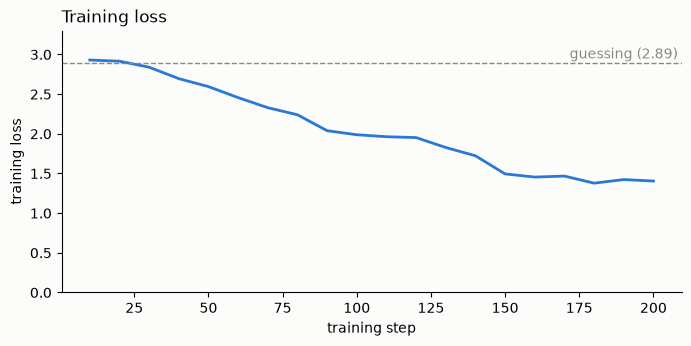

In [7]:

losses = [(log["step"], log["loss"]) for log in trainer.state.log_history if "loss" in log]
plt.figure(figsize=(8, 3.4))
if losses:
    plt.plot(*zip(*losses), color=BLUE, lw=2)
plt.axhline(np.log(len(LABELS)), color=GREY, ls="--", lw=1)
plt.text(plt.xlim()[1], np.log(len(LABELS)) + 0.06, "guessing (2.89) ", color=GREY, ha="right")
plt.ylim(0, 3.3)
plt.xlabel("training step")
plt.ylabel("training loss")
plt.title("Training loss")
plt.show()

Now score the validation passages. `predict` gives the model's probabilities for each passage, and its answer is the LLM with the highest one. **Balanced accuracy** is the share of each LLM's passages it names correctly, averaged over the 18 LLMs.

In [8]:
def predict(texts):
    """The model's probabilities: one row per passage, one column per LLM."""
    logits = torch.tensor(trainer.predict(Passages(texts)).predictions).float()
    return torch.softmax(logits, dim=1).numpy()

def answers(probs):
    return np.array(LABELS)[probs.argmax(axis=1)]

probs = predict(val_df.text)
score = balanced_accuracy_score(val_df.model, answers(probs))
seen = train_df.sample(len(val_df), random_state=0)  # passages it trained on
seen_score = balanced_accuracy_score(seen.model, answers(predict(seen.text)))
print(f"balanced accuracy on unseen prompts: {score:.3f}")
print(f"balanced accuracy on passages it trained on: {seen_score:.3f}")

balanced accuracy on unseen prompts: 0.319
balanced accuracy on passages it trained on: 0.586


A single fine-tuning run lands somewhere around **0.29–0.35** on these validation passages, against 0.06 for guessing at random.

It also gets only about half of the passages it *trained on* right: we come back to that in section 5.

These two held-out passages show one correct prediction and one incorrect prediction, each with the model’s top three guesses.

In [9]:
correct = answers(probs) == val_df.model.to_numpy()
rng = np.random.default_rng(0)

for mark, mask in [("✓", correct), ("✗", ~correct)]:
    matches = np.flatnonzero(mask)
    if len(matches) == 0:
        continue
    i = rng.choice(matches)
    top3 = np.argsort(-probs[i], kind="stable")[:3]
    print(mark, "written by", val_df.model.iloc[i])
    print("   ", val_df.text.iloc[i][:220], "…")
    print("    guesses:", " · ".join(f"{LABELS[j]} {probs[i, j]:.0%}" for j in top3))
    print()

✓ written by glm-5.3-flash
    guesses: glm-5.3-flash 28% · glm-5.3 24% · claude-opus-4-6 16%

✗ written by claude-opus-4-6
    guesses: glm-5.3-flash 18% · claude-opus-4-6 18% · claude-fable-5 18%



## 3. Cross-validation

`GroupKFold` makes 5 splits like the one in section 2. Each holds back a different group of 30 prompts and all their passages, so every prompt appears in validation exactly once. Split 0 is section 2's split.

In [10]:
from sklearn.model_selection import GroupKFold

splits = list(GroupKFold(n_splits=5).split(labeled_df, groups=labeled_df.prompt_id))
assert set(labeled_df.prompt_id.iloc[splits[0][1]]) == set(val_prompts)  # section 2 uses split 0

for k, (train_idx, val_idx) in enumerate(splits):
    print(f"Split {k} trains on {labeled_df.prompt_id.iloc[train_idx].nunique()} prompts "
          f"and validates on {labeled_df.prompt_id.iloc[val_idx].nunique()} held-out prompts ({len(val_idx)} passages)")

Split 0 trains on 120 prompts and validates on 30 held-out prompts (540 passages)
Split 1 trains on 120 prompts and validates on 30 held-out prompts (540 passages)
Split 2 trains on 120 prompts and validates on 30 held-out prompts (540 passages)
Split 3 trains on 120 prompts and validates on 30 held-out prompts (540 passages)
Split 4 trains on 120 prompts and validates on 30 held-out prompts (539 passages)


Before the session we trained section 2's exact recipe 15 times: 3 seeds × 5 splits. Each run's score on each split is saved in `oof/arch_matrix_extra.csv` (run `B0`):

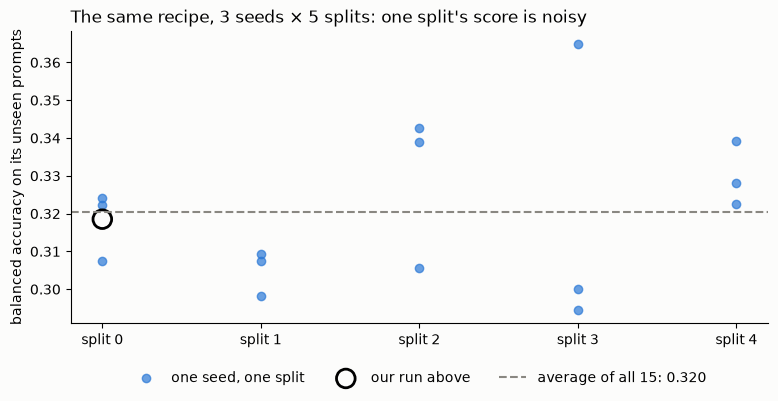

5-split average for each seed: 0.313, 0.312, 0.336


In [11]:
runs = pd.read_csv(RESULTS / "arch_matrix_extra.csv")
recipe_runs = runs[runs.seed == 0].set_index("config")  # matched runs for section 4
baseline = runs[runs.config == "B0"]                 # 3 seeds of section 2's recipe
per_split = baseline[[f"split{k}" for k in range(5)]]

plt.figure(figsize=(9, 3.8))
for k in range(5):
    plt.scatter([k] * len(baseline), per_split[f"split{k}"], color=BLUE, alpha=0.7,
                label="one seed, one split" if k == 0 else None)
plt.scatter([0], [score], s=180, facecolors="none", edgecolors="black", lw=2, label="our run above")
plt.axhline(per_split.to_numpy().mean(), color=GREY, ls="--", label=f"average of all 15: {per_split.to_numpy().mean():.3f}")
plt.xticks(range(5), [f"split {k}" for k in range(5)])
plt.ylabel("balanced accuracy on its unseen prompts")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.title("The same recipe, 3 seeds × 5 splits: one split's score is noisy")
plt.show()
print("5-split average for each seed:", ", ".join(f"{s:.3f}" for s in baseline.score))

The same recipe, on the same data:
- **One split's score ranges from about 0.29 to 0.37,** depending on which 30 prompts landed in the validation set and on the random seed.
- **Our run above is just one more draw** from that spread.
- **Averaging all 5 splits steadies it,** though the three seeds' averages still differ by up to 0.02.

Averaging the validation scores over all five splits gives the **cross-validation score** for a recipe.

## 4. Learning rate × epochs

Two settings matter most in fine-tuning:
- **learning rate:** how big each update is. Too small and the model barely moves; too big and it forgets what it knew.
- **epochs:** how many passes over the training data.

We tried two learning rates and two epoch counts. Each bar shows one recipe’s balanced accuracy, averaged over the same five validation splits.

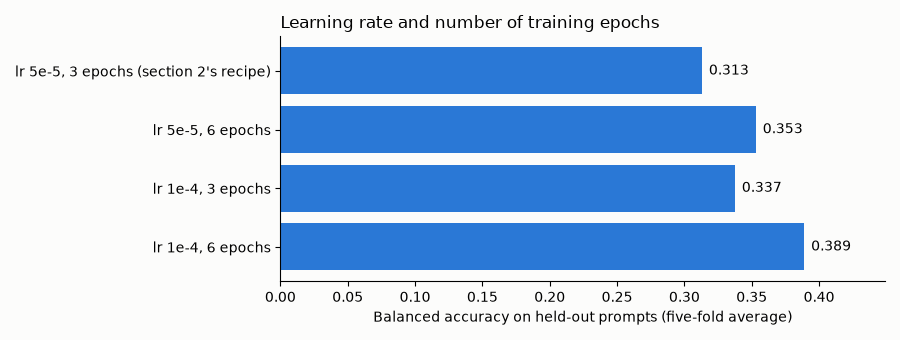

In [12]:
RECIPES = {"B0": "lr 5e-5, 3 epochs (section 2's recipe)", "T1": "lr 5e-5, 6 epochs",
           "T2": "lr 1e-4, 3 epochs", "T3": "lr 1e-4, 6 epochs"}
recipe_scores = recipe_runs.loc[list(RECIPES), "score"]

fig, ax = plt.subplots(figsize=(9, 3.4))
recipe_bars = ax.barh(list(RECIPES.values()), recipe_scores, color=BLUE)
ax.invert_yaxis()
ax.bar_label(recipe_bars, fmt="%.3f", padding=5)
ax.set_xlim(0, recipe_scores.max() + 0.06)
ax.set_xlabel("Balanced accuracy on held-out prompts (five-fold average)")
ax.set_title("Learning rate and number of training epochs")
fig.tight_layout()
plt.show()

- At a learning rate of 5e-5, training for six epochs raised balanced accuracy from **0.313 to 0.353**.
- At 1e-4, balanced accuracy rose from **0.337 to 0.389**. Six epochs at this learning rate gave the highest score of the four recipes.

## 5. Memorising vs generalising

Every run also scored itself on a sample of passages it **trained on** (column `seen`). Comparing that with its score on **unseen** prompts shows whether a model is still learning or just memorising.

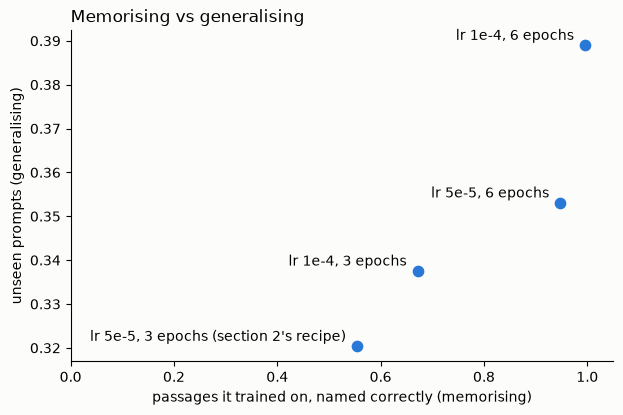

In [13]:
means = runs[runs.config.isin(RECIPES)].groupby("config")[["seen", "score"]].mean()
plt.figure(figsize=(7, 4.3))
plt.scatter(means.seen, means.score, color=BLUE, s=55, zorder=3)
for config, row in means.iterrows():
    plt.annotate(RECIPES[config], (row.seen, row.score), xytext=(-8, 4), textcoords="offset points", ha="right")
plt.xlim(0, 1.05)
plt.xlabel("passages it trained on, named correctly (memorising)")
plt.ylabel("unseen prompts (generalising)")
plt.title("Memorising vs generalising")
plt.show()

Section 2's recipe gets only about 55% of its *own training passages* right. It isn't memorising too much: it's **under-trained**. Here, memorising more (moving right) went with doing better on unseen prompts (moving up).

Does that last? One run of 12 epochs at learning rate 1e-4, scored after every epoch on both, shows the whole story (saved as `arch_CP_s0.json`):

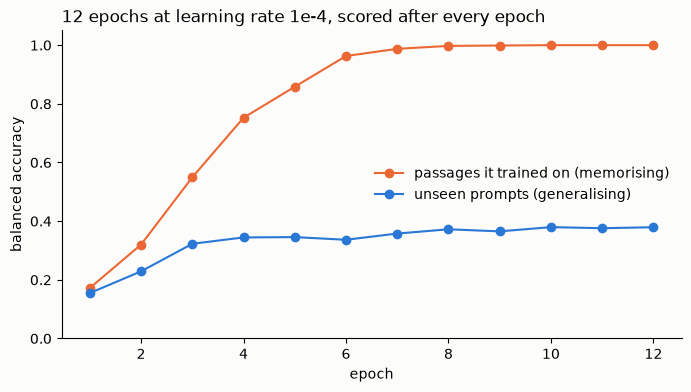

In [14]:
saved_run = json.loads((RESULTS / "arch_CP_s0.json").read_text())
points = [(epoch, unseen, seen) for split in saved_run["epoch_scores"].values() for epoch, unseen, seen in split]
curve = pd.DataFrame(points, columns=["epoch", "unseen", "seen"]).groupby("epoch").mean()  # average of 5 splits

plt.figure(figsize=(8, 4))
plt.plot(curve.index, curve.seen, color=ORANGE, marker="o", label="passages it trained on (memorising)")
plt.plot(curve.index, curve.unseen, color=BLUE, marker="o", label="unseen prompts (generalising)")
plt.ylim(0, 1.05)
plt.xlabel("epoch")
plt.ylabel("balanced accuracy")
plt.legend(frameon=False, loc="center right")
plt.title("12 epochs at learning rate 1e-4, scored after every epoch")
plt.show()

- **By epoch 8 the model has memorised its training passages:** it names 100% of them correctly.
- **After memorising, extra epochs add little:** there's almost nothing left in the training data to learn from. To go further, we need **more data**.

## 6. More data

The **Open Pool** is a public Kaggle dataset of about 239,000 passages from the same 18 LLMs, generated and shared by other competitors (the rules allow it). We add 500 or 2,000 passages per model (9,000 or 36,000 in total) to every split's *training* data, picked so their punctuation and length match the official passages. Validation uses only held-out official passages.

The 2,000-per-model run was scored on splits 0 and 1, so all four bars use those same two validation splits.

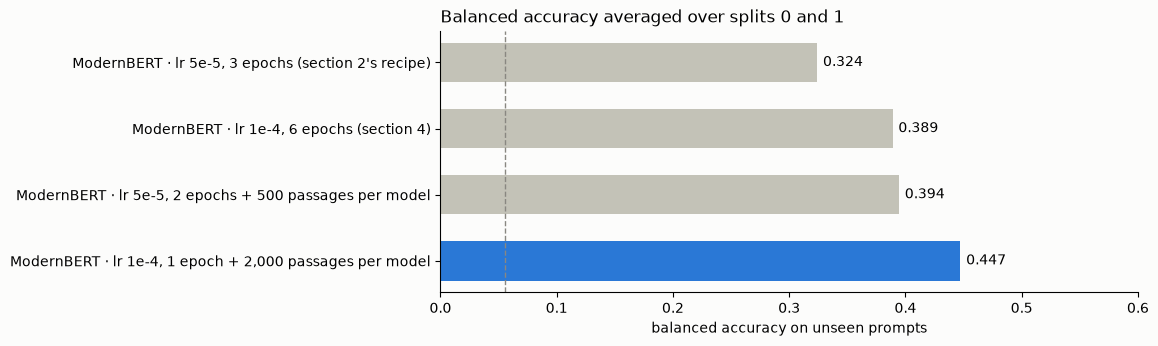

In [15]:
def saved(name):
    """A saved model's predictions: one row per passage (in train.csv order), one column per LLM."""
    return pd.read_parquet(RESULTS / f"{name}.parquet")[LABELS].to_numpy()

def bars(scores, title):
    """One bar per model; the last (newest) in blue."""
    names = list(scores)
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(names) + 1.2))
    ax.barh(names[::-1], [scores[n] for n in names[::-1]], color=[BLUE] + [LIGHT] * (len(names) - 1), height=0.6)
    for y, n in enumerate(names[::-1]):
        ax.text(scores[n] + 0.005, y, f"{scores[n]:.3f}", va="center")
    ax.axvline(1 / len(LABELS), color=GREY, ls="--", lw=1)  # guessing
    ax.set_xlim(0, 0.6)
    ax.set_xlabel("balanced accuracy on unseen prompts")
    ax.set_title(title)
    plt.show()

def cv_score(probs, which=(0, 1)):
    """Balanced accuracy on each split's validation passages, averaged over the splits."""
    return np.mean([balanced_accuracy_score(labeled_df.model.iloc[splits[k][1]], answers(probs[splits[k][1]]))
                    for k in which])

bars({
    "ModernBERT · lr 5e-5, 3 epochs (section 2's recipe)": cv_score(saved("modernbert_official")),
    "ModernBERT · lr 1e-4, 6 epochs (section 4)": cv_score(saved("arch_T3_s0")),
    "ModernBERT · lr 5e-5, 2 epochs + 500 passages per model": cv_score(saved("modernbert_pool500")),
    "ModernBERT · lr 1e-4, 1 epoch + 2,000 passages per model": cv_score(saved("arch_P2k_s0")),
}, "Balanced accuracy averaged over splits 0 and 1")

## Take-home messages

- **Validate on prompts the model has never seen, and average over several splits.** The same recipe scored anywhere from about 0.29 to 0.37 on a single split.
- **Learning rate and epochs matter most:** raising the learning rate and training for six epochs took ModernBERT from 0.31 to 0.39.
- **Memorising isn't the enemy here, but it is a ceiling:** once the model has memorised its training passages, more epochs stop helping.
- **The run with 2,000 extra passages per model scored 0.45**, compared with 0.32 for the section 2 recipe on the same two splits.